# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [5]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
%pip install statsmodels
#!sudo apt-get install -y fonts-nanum
#!sudo fc-cache -fv
#!rm ~/.cache/matplotlib -rf

Note: you may need to restart the kernel to use updated packages.


In [7]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

c:\Users\chaee\anaconda3\envs\myenv2\Lib\site-packages\polars\meta\build.py:5: UserWarning: Polars binary is missing!
  from polars._utils.polars_version import get_polars_version


# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

In [16]:
# 문제 설정
n = 200  # 총 시행 횟수
x = 12   # 관찰된 성공 횟수
p = 0.1  # 귀무가설에서의 성공 확률

print(f"관찰 결과: {n}번 시도 중 {x}번 성공 (관찰 성공률 {x/n:.1%})")

관찰 결과: 200번 시도 중 12번 성공 (관찰 성공률 6.0%)


**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

In [24]:
# [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): **아이템의 뽑기 성공 확률은 10%이다**
# H₁ (대립가설):**아이템의 뽑기 성공 확률은 10%보다 낮다**

In [ ]:
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?
## alternative= ' ' : 대립 가설의 방향. 의심 방향이 더 낮다면 less, 더 높다면 greater
# 여기에 코드를 작성해주세요.

from scipy import stats

# 이항검정 수행 함수(k:관찰횟수, n:전체시행횟수, p:귀무가설에서 가정한 성공확률)
result = stats.binomtest(k=x, n=n, p=p, alternative='less')

#result.pvalue로 p-값 꺼내기
print(f"p-값: {result.pvalue:.4f}")



p-값: 0.0320


In [27]:
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.

alpha = 0.05
if result.pvalue < alpha:
    print(f"p-값({result.pvalue:.4f}) < 유의수준({alpha}) → 귀무가설 기각")
    print("→ 실제 확률이 10%보다 낮다고 볼 통계적 근거가 있습니다.")
else:
    print(f"p-값({result.pvalue:.4f}) ≥ 유의수준({alpha}) → 귀무가설 기각 실패")
    print("→ 확률이 10%보다 낮다고 단정할 근거가 부족합니다.")

p-값(0.0320) < 유의수준(0.05) → 귀무가설 기각
→ 실제 확률이 10%보다 낮다고 볼 통계적 근거가 있습니다.


In [29]:
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# 힌트: numpy의 이항분포 랜덤 함수(np.random.binomial)를 사용해보세요.

# 여기에 코드를 작성해주세요.

import numpy as np

np.random.seed(42)          # 실행할 때마다 같은 결과가 나오도록 고정
n_sim = 10000               # 시뮬레이션 반복 횟수

# 확률 10%로 200번 뽑았을 때의 성공 횟수를 10,000번 생성
simulated = np.random.binomial(n=n, p=p, size=n_sim)

print("처음 10번의 시뮬레이션 결과:", simulated[:10])
print(f"평균 성공 횟수: {simulated.mean():.2f}")
print(f"표준편차: {simulated.std():.2f}")

# 관찰값(12번) 이하로 나온 경우의 비율 = 시뮬레이션으로 구한 p-값
count = np.sum(simulated <= x)
sim_p_value = count / n_sim

print(f"\n12번 이하로 성공한 횟수: {count}번 / {n_sim}번")
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")
print(f"이항검정 p-값:   {result.pvalue:.4f}")

처음 10번의 시뮬레이션 결과: [19 27 23 21 16 16 14 25 21 22]
평균 성공 횟수: 19.91
표준편차: 4.21

12번 이하로 성공한 횟수: 313번 / 10000번
시뮬레이션 p-값: 0.0313
이항검정 p-값:   0.0320


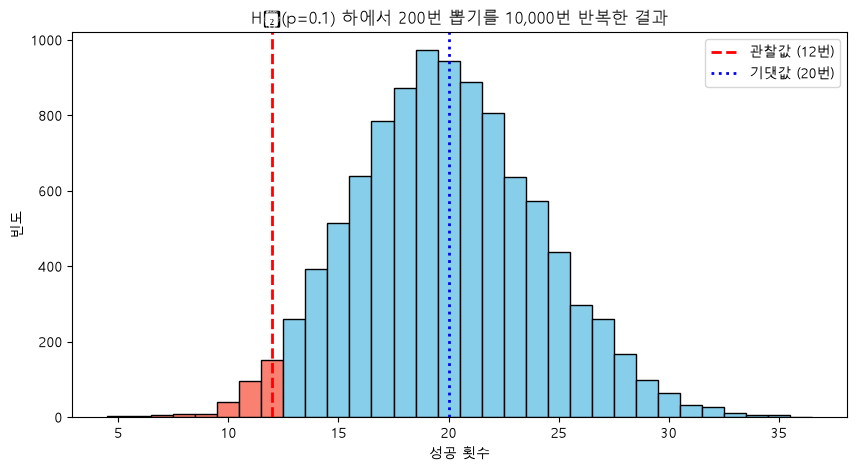

빨간 영역(12번 이하)의 비율 = 0.0313


In [30]:
# [문제 1] Q5. 시뮬레이션 결과를 히스토그램으로 그려봅시다.
# 실제 관찰값(12번 성공)을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# 성공 횟수별로 막대 하나씩 그리기 (0.5 간격으로 경계를 잡아 정수가 막대 가운데 오도록)
bins = np.arange(simulated.min() - 0.5, simulated.max() + 1.5, 1)
counts, edges, patches = plt.hist(simulated, bins=bins,
                                  color='skyblue', edgecolor='black')

# 관찰값(12) 이하인 막대는 빨간색으로 칠하기 → p-값에 해당하는 영역
for patch, left_edge in zip(patches, edges[:-1]):
    if left_edge + 0.5 <= x:
        patch.set_facecolor('salmon')

# 관찰값 세로선
plt.axvline(x, color='red', linestyle='--', linewidth=2,
            label=f'관찰값 ({x}번)')

# 기댓값 세로선 (참고용)
plt.axvline(n * p, color='blue', linestyle=':', linewidth=2,
            label=f'기댓값 ({n * p:.0f}번)')

plt.title(f'H₀(p=0.1) 하에서 200번 뽑기를 {n_sim:,}번 반복한 결과')
plt.xlabel('성공 횟수')
plt.ylabel('빈도')
plt.legend()
plt.show()

print(f"빨간 영역(12번 이하)의 비율 = {sim_p_value:.4f}")

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?
> 그래프에서 관찰값인 12회 이하에 해당하는 빨간색 영역이다. 귀무가설에서 참일 때 12회 이하의 성공이 발생할 확률을 의미

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?
> 12회 이하로 성공할 확률은 3.2%이다. 따라서 비교적 드문 결과

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?
> 

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?
> p-값이 훨씬 작아진다. 시행 횟수가 많아지면 결과가 기댓값 근처로 더 좁게 모이기 때문

In [22]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

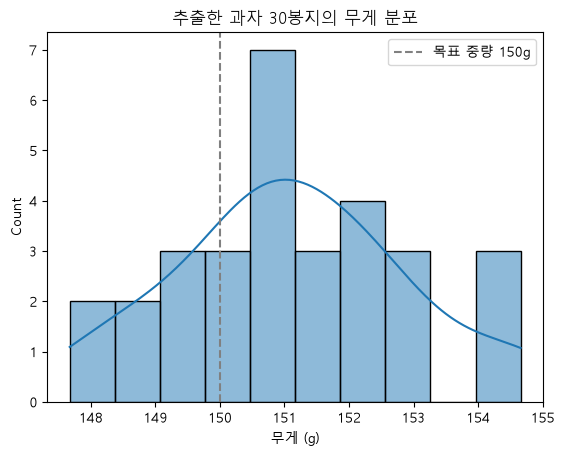

In [31]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [ ]:
# [문제 2] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 과자 한 봉지의 평균 중량은 150g이다.
# H₁ (대립가설): 과자 한 봉지의 평균 중량은 150g이 아니다.

In [ ]:
# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.

# 여기에 코드를 작성해주세요.

# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
from scipy import stats

#일표본 t-검정을 수행하는 함수(측정한 30봉지의 무게 데이터, 비교할 기준값인 목표 중량)
t_stat, p_value = stats.ttest_1samp(sample_weights, popmean=pop_mean)

print(f"표본 평균: {sample_weights.mean():.2f}g")
print(f"t-통계량: {t_stat:.4f}")
print(f"p-값: {p_value:.4f}")

표본 평균: 151.12g
t-통계량: 3.4193
p-값: 0.0019


**t-통계량이란**
> 표본 평균이 기준값에서 얼마나 떨어져 있는지를 표준오차 단위로 나타낸 값

In [33]:
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.

alpha = 0.05

print(f"p-값: {p_value:.4f}, 유의수준: {alpha}")

if p_value < alpha:
    print("결론: 귀무가설을 기각합니다.")
    print("→ 과자 한 봉지의 평균 중량이 목표 중량(150g)과 다르다는 통계적으로 유의미한 증거가 있습니다.")
else:
    print("결론: 귀무가설을 기각하지 못합니다.")
    print("→ 과자 한 봉지의 평균 중량이 목표 중량(150g)과 다르다고 말할 충분한 증거가 없습니다.")

p-값: 0.0019, 유의수준: 0.05
결론: 귀무가설을 기각합니다.
→ 과자 한 봉지의 평균 중량이 목표 중량(150g)과 다르다는 통계적으로 유의미한 증거가 있습니다.


In [34]:
# [문제 2] Q4. H₀가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장해봅시다.
# 힌트: 표준편차는 우리가 가진 표본의 표준편차를 사용한다고 가정하고, for 반복문을 사용해보세요.

# 여기에 코드를 작성해주세요.
np.random.seed(0)

n_sim = 10000                          # 시뮬레이션 반복 횟수
n_sample = len(sample_weights)         # 표본 크기 (30)
sample_std = sample_weights.std(ddof=1)  # 우리 표본의 표준편차
sample_mean = sample_weights.mean()      # 우리 표본의 평균 (151.12g)

sim_means = []  # 각 표본의 평균을 저장할 리스트

for i in range(n_sim):
    # 평균 150g, 표준편차 sample_std인 분포에서 30봉지를 무작위로 뽑기
    sim_sample = np.random.normal(loc=pop_mean, scale=sample_std, size=n_sample)
    # 그 30봉지의 평균을 리스트에 추가
    sim_means.append(sim_sample.mean())

sim_means = np.array(sim_means)  # 계산하기 편하게 배열로 변환

print(f"우리 표본의 표준편차: {sample_std:.2f}g")
print(f"시뮬레이션 표본 평균들의 평균: {sim_means.mean():.2f}g")
print(f"시뮬레이션 표본 평균들의 표준편차: {sim_means.std():.2f}g")

# 150g에서 우리 표본만큼(1.12g 이상) 벗어난 경우의 비율 (양쪽 모두)
diff = abs(sample_mean - pop_mean)
sim_p_value = np.mean(abs(sim_means - pop_mean) >= diff)
print(f"\n150g에서 {diff:.2f}g 이상 벗어난 비율: {sim_p_value:.4f}")


우리 표본의 표준편차: 1.80g
시뮬레이션 표본 평균들의 평균: 150.00g
시뮬레이션 표본 평균들의 표준편차: 0.33g

150g에서 1.12g 이상 벗어난 비율: 0.0003


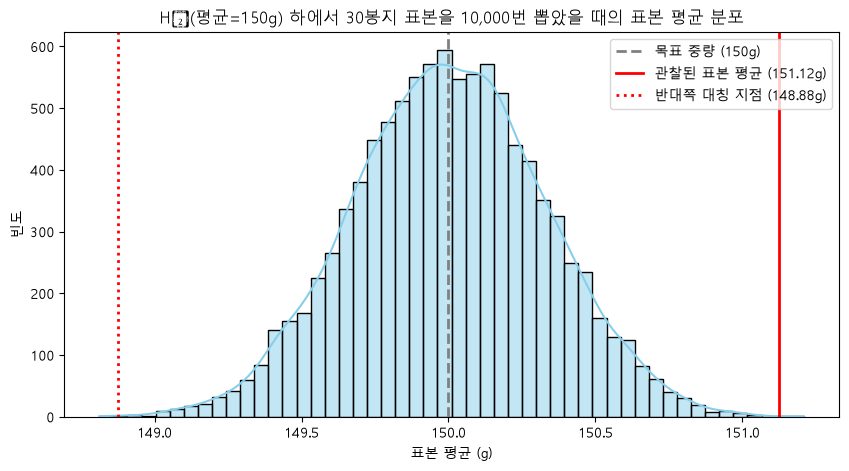

In [35]:
# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.
plt.figure(figsize=(10, 5))

# 시뮬레이션 표본 평균 분포
sns.histplot(sim_means, bins=50, kde=True, color='skyblue')

# 목표 중량(150g) 세로선
plt.axvline(pop_mean, color='gray', linestyle='--', linewidth=2,
            label=f'목표 중량 ({pop_mean}g)')

# 실제 관찰된 표본 평균 세로선
plt.axvline(sample_mean, color='red', linestyle='-', linewidth=2,
            label=f'관찰된 표본 평균 ({sample_mean:.2f}g)')

# 양측 검정이므로 반대쪽(150g보다 1.12g 가벼운 지점)도 표시
plt.axvline(pop_mean - diff, color='red', linestyle=':', linewidth=2,
            label=f'반대쪽 대칭 지점 ({pop_mean - diff:.2f}g)')

plt.title(f'H₀(평균=150g) 하에서 30봉지 표본을 {n_sim:,}번 뽑았을 때의 표본 평균 분포')
plt.xlabel('표본 평균 (g)')
plt.ylabel('빈도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)
> 귀무가설이 참이고 과자의 평균 중량이 150g이라고 가정했을 때, 과자 30봉지의 표본 평균이 어떻게 분포하는지를 나타낸다.
> 즉, 귀무가설이 사실일 때 "우연만으로 나올 수 있는 표본 평균의 범위"를 보여줌
> 모양이 정규분포와 비슷한 이유는 **중심극한정리** 때문임.
> 중심극한정리에 따르면 표본의 크기가 충분히 크면 원래 데이터가 어떤 분포를 따르든 표본 평균의 분포는 정규분포에 가까워진다.


- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?
> **흔하지 않은 값이다.** 
> p-값이 약 0.0019로 작다는 것은 이러한 결과가 귀무가설 아래에서 드물게 발생한다는 뜻

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?
> 현재(0.0019)보다 중심에서 조금 더 오른쪽 바깥에 위치할 것이다.
> 표본 평균을 나타내는 세로선은 분포의 중심인 150g에서 훨씬 멀리 떨어진 꼬리 부분에 위치할 것이다. 귀무가설이 참일 대 이러한 결과가 매우 드물기 때문

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)
> 목표보다 무겁게 생산되고 있다는 통계적 근거가 있으므로 생산 공정을 점검할 필요가 있음. 과자를 목표보다 무겁게 생산하면 원재료 사용량이 증가하고 생산 비용이 높아질 수 있습니다. 따라서 중량 측정 장비와 포장 공정을 확인하여 평균 중량을 목표에 맞게 조정하는 것이 좋습니다.

In [ ]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

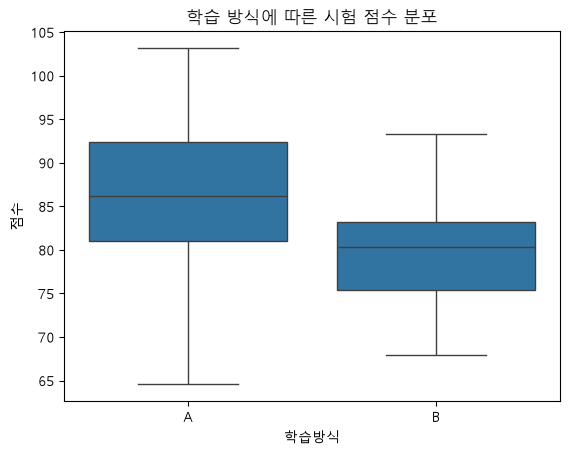

In [36]:
# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

df_scores = pd.DataFrame({'점수': np.concatenate([group_a_scores, group_b_scores]),
                          '학습방식': ['A']*50 + ['B']*50})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x='학습방식', y='점수', data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

In [37]:
# [문제 3] Q1. 두 그룹에 대해 각각 정규성 검정(Shapiro-Wilk test)을 수행하고 p-값을 출력해봅시다.
# H₀: 데이터는 정규분포를 따른다.

# 여기에 코드를 작성해주세요.

from scipy import stats

shapiro_a = stats.shapiro(group_a_scores)
shapiro_b = stats.shapiro(group_b_scores)

print(f"그룹 A 정규성 검정 p-값: {shapiro_a.pvalue:.4f}")
print(f"그룹 B 정규성 검정 p-값: {shapiro_b.pvalue:.4f}")

alpha = 0.05
for name, res in [('A', shapiro_a), ('B', shapiro_b)]:
    if res.pvalue >= alpha:
        print(f"→ 그룹 {name}: 귀무가설을 기각하지 못함 → 정규성을 만족한다고 볼 수 있음")
    else:
        print(f"→ 그룹 {name}: 귀무가설 기각 → 정규성을 만족하지 않음")

그룹 A 정규성 검정 p-값: 0.8766
그룹 B 정규성 검정 p-값: 0.8366
→ 그룹 A: 귀무가설을 기각하지 못함 → 정규성을 만족한다고 볼 수 있음
→ 그룹 B: 귀무가설을 기각하지 못함 → 정규성을 만족한다고 볼 수 있음


In [38]:
# [문제 3] Q2. 두 그룹에 대해 등분산성 검정(Levene's test)을 수행하고 p-값을 출력해봅시다.
# H₀: 두 그룹의 분산은 같다.

# 여기에 코드를 작성해주세요.

levene_result = stats.levene(group_a_scores, group_b_scores)

print(f"그룹 A 분산: {group_a_scores.var(ddof=1):.2f}")
print(f"그룹 B 분산: {group_b_scores.var(ddof=1):.2f}")
print(f"등분산성 검정 p-값: {levene_result.pvalue:.4f}")

alpha = 0.05
if levene_result.pvalue >= alpha:
    print("→ 귀무가설을 기각하지 못함 → 등분산성을 만족한다고 볼 수 있음")
else:
    print("→ 귀무가설 기각 → 두 그룹의 분산이 다름 (등분산성 불만족)")

그룹 A 분산: 82.73
그룹 B 분산: 37.59
등분산성 검정 p-값: 0.0150
→ 귀무가설 기각 → 두 그룹의 분산이 다름 (등분산성 불만족)


**등분산성 검정**
> A와 B의 퍼진 정도가 같은가를 묻는 검정. 그룹 하나만으로는 답 할 수 없고 두 그룹을 비교해야 하는 질문.

In [39]:
# [문제 3] Q3. 이표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
# 등분산성 가정을 만족했는지 여부에 따라 equal_var 인수를 설정해보세요.

# 여기에 코드를 작성해주세요.

equal_var = levene_result.pvalue >= alpha   # p-값 0.0150 < 0.05 → False

t_stat, p_value = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)

print(f"그룹 A 평균: {group_a_scores.mean():.2f}점")
print(f"그룹 B 평균: {group_b_scores.mean():.2f}점")
print(f"평균 차이: {group_a_scores.mean() - group_b_scores.mean():.2f}점")
print(f"\nequal_var = {equal_var} → {'Student의 t-검정' if equal_var else 'Welch의 t-검정'}")
print(f"t-통계량: {t_stat:.4f}")
print(f"p-값: {p_value:.4f}")

그룹 A 평균: 86.12점
그룹 B 평균: 79.85점
평균 차이: 6.27점

equal_var = False → Welch의 t-검정
t-통계량: 4.0426
p-값: 0.0001


In [40]:
# [문제 3] Q4. H₀가 사실(두 그룹의 평균이 같다)이라고 가정하고 시뮬레이션을 10,000번 수행해봅시다.
# 두 그룹의 데이터를 모두 합친 뒤(np.concatenate), 매 반복마다 비복원추출로 50개(가상 A그룹)와
# 나머지 50개(가상 B그룹)로 나누어 두 그룹의 평균 차이를 계산하고 리스트에 저장해보세요.
# 힌트: np.random.permutation 을 사용해보세요.

# 여기에 코드를 작성해주세요.
np.random.seed(42)

n_sim = 10000
n_a = len(group_a_scores)   # 50

# 실제 관찰된 평균 차이
observed_diff = group_a_scores.mean() - group_b_scores.mean()

# 두 그룹의 점수를 하나로 합치기 (총 100개)
all_scores = np.concatenate([group_a_scores, group_b_scores])

sim_diffs = []  # 각 반복의 평균 차이를 저장할 리스트

for i in range(n_sim):
    # 100개의 점수를 무작위로 섞기 (비복원추출)
    shuffled = np.random.permutation(all_scores)
    # 앞 50개는 가상 A그룹, 나머지 50개는 가상 B그룹
    fake_a = shuffled[:n_a]
    fake_b = shuffled[n_a:]
    # 두 가상 그룹의 평균 차이 저장
    sim_diffs.append(fake_a.mean() - fake_b.mean())

sim_diffs = np.array(sim_diffs)

print(f"실제 관찰된 평균 차이: {observed_diff:.2f}점")
print(f"시뮬레이션 평균 차이들의 평균: {sim_diffs.mean():.2f}점")
print(f"시뮬레이션 평균 차이들의 범위: {sim_diffs.min():.2f} ~ {sim_diffs.max():.2f}점")

# 실제 차이만큼(6.27점 이상) 벌어진 경우의 비율 (양측)
count = np.sum(abs(sim_diffs) >= abs(observed_diff))
sim_p_value = count / n_sim
print(f"\n|차이| ≥ {abs(observed_diff):.2f}점인 경우: {count}번 / {n_sim}번")
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")


실제 관찰된 평균 차이: 6.27점
시뮬레이션 평균 차이들의 평균: -0.02점
시뮬레이션 평균 차이들의 범위: -6.14 ~ 6.51점

|차이| ≥ 6.27점인 경우: 1번 / 10000번
시뮬레이션 p-값: 0.0001


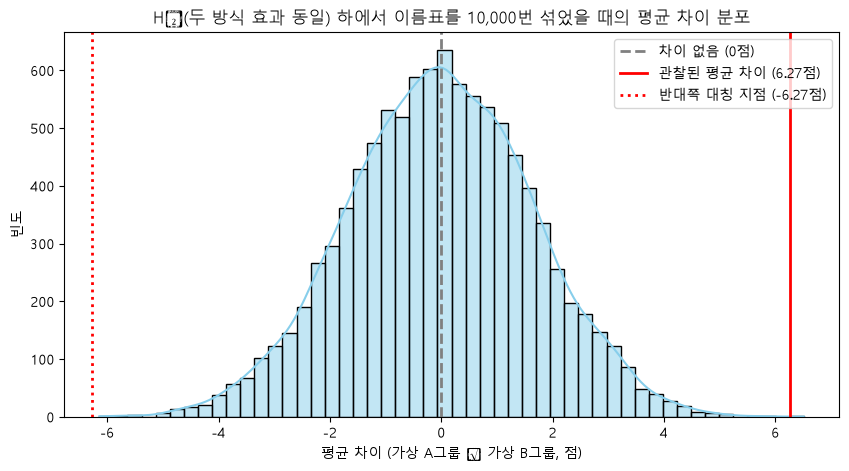

In [41]:
# [문제 3] Q5. 시뮬레이션으로 얻은 평균 차이의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 평균 차이(A그룹 평균 - B그룹 평균)를 세로선으로 함께 표시해 봅시다.
plt.figure(figsize=(10, 5))

# 시뮬레이션 평균 차이 분포
sns.histplot(sim_diffs, bins=50, kde=True, color='skyblue')

# 차이 0 (H₀: 두 방식의 효과가 같음)
plt.axvline(0, color='gray', linestyle='--', linewidth=2,
            label='차이 없음 (0점)')

# 실제 관찰된 평균 차이
plt.axvline(observed_diff, color='red', linestyle='-', linewidth=2,
            label=f'관찰된 평균 차이 ({observed_diff:.2f}점)')

# 양측 검정이므로 반대쪽 대칭 지점도 표시
plt.axvline(-observed_diff, color='red', linestyle=':', linewidth=2,
            label=f'반대쪽 대칭 지점 ({-observed_diff:.2f}점)')

plt.title(f'H₀(두 방식 효과 동일) 하에서 이름표를 {n_sim:,}번 섞었을 때의 평균 차이 분포')
plt.xlabel('평균 차이 (가상 A그룹 − 가상 B그룹, 점)')
plt.ylabel('빈도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?
> **정규성 검정**: 그룹 A(p=0.8766), 그룹 B(p=0.8366) 모두 p-값이 0.05보다 크므로 귀무가설("정규분포를 따른다")을 기각하지 못합니다.
> 따라서 두 그룹 모두 정규성 가정을 만족한다고 볼 수 있습니다.
> **등분산성 검정**: p-값이 0.0150으로 0.05보다 작으므로 귀무가설("두 그룹의 분산은 같다")을 기각합니다.
> 실제로 그룹 A의 분산(82.73)이 그룹 B(37.59)의 두 배 이상으로, 등분산성 가정은 만족하지 않습니다.
> 따라서 분산이 같다고 가정하는 **기본(Student의) t-검정을 그대로 쓰는 것은 적절하지 않습니다.**
> 다만 정규성은 만족하므로, 분산이 다른 경우에 사용하는 **Welch의 t-검정**(equal_var=False)을 사용하면 문제없이 검정할 수 있습니다.


- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?
> 시뮬레이션에서는 A와 B의 점수를 모두 합친 다음 **무작위**로 나누고 있기 때문에
>즉, 두 학습 방식의 효과가 같다는 귀무가설을 가정하는 상황.
>이 상황에서는 가상 A와 가상 B가 특별히 더 높은 점수를 받을 이유가 없어.
- 가상 A가 우연히 높으면 차이는 양수
- 가상 B가 우연히 높으면 차이는 음수
- 평균적으로는 양수와 음수가 서로 상쇄됨
> 그래서 시뮬레이션 평균 차이의 중심이 0점 근처에 나타나는 거야.

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?
> **벗어납니다.** 이름표를 섞었을 때의 평균 차이는 대부분 0을 중심으로 약 −4~+4점 사이에 분포합니다.
> 실제 관찰된 차이 6.27점은 분포의 오른쪽 끝, 막대가 거의 없는 곳에 위치하며,
> 10,000번의 시뮬레이션 중 이만큼 차이가 벌어진 경우는 단 1번뿐이었습니다.
> 따라서 이 차이는 우연만으로 나타나기 매우 어려운 값입니다.

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?
> Q3의 p-값(약 0.0001)은 히스토그램에서 **세로선 바깥쪽 영역의 비율**에 해당합니다.
> 양측 검정이므로 +6.27점보다 오른쪽과 −6.27점보다 왼쪽 영역을 합친 넓이입니다.
> 시뮬레이션으로 직접 센 비율(0.0001)과 t-검정 공식으로 계산한 p-값(0.0001)이 거의 같다는 것은,
> "세로선이 분포 바깥쪽에 있다"는 시각적 판단과 "p-값이 매우 작다"는 통계적 판단이 같은 의미라는 것을 보여줍니다.
> 세로선이 분포 중심에서 멀어질수록 바깥 영역이 좁아지고 p-값도 작아집니다.

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

In [ ]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
     액션  로맨스
20대  70   30
30대  50   60
40대  30   60


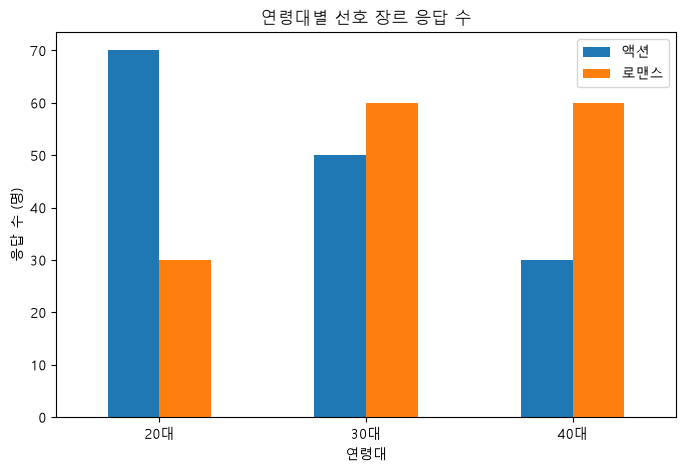

In [42]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [ ]:
# [문제 4] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 연령대와 선호 장르는 서로 독립이다. (연령대에 따라 선호 장르에 차이X)
# H₁ (대립가설): 연령대와 선호장르는 서로 독립이 아니다.(연령대에 따라 선호장르 차이 O)

In [43]:
# [문제 4] Q2. 카이제곱 독립성 검정을 수행하고 카이제곱 통계량, p-값, 자유도, 기대 빈도를 구해봅시다.
# 기대 빈도는 관측 빈도와 비교하기 쉽도록 데이터프레임 형태로 출력해보세요.

# 여기에 코드를 작성해주세요.
from scipy import stats

chi2_stat, p_value, dof, expected = stats.chi2_contingency(observed)

print(f"카이제곱 통계량: {chi2_stat:.4f}")
print(f"p-값: {p_value:.8f}")
print(f"자유도: {dof}")

# 기대 빈도를 관측 빈도와 같은 형태의 데이터프레임으로 변환
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

print("\n관측 빈도 (Observed):")
print(observed)
print("\n기대 빈도 (Expected):")
print(expected_df)


카이제곱 통계량: 26.9091
p-값: 0.00000143
자유도: 2

관측 빈도 (Observed):
     액션  로맨스
20대  70   30
30대  50   60
40대  30   60

기대 빈도 (Expected):
       액션   로맨스
20대  50.0  50.0
30대  55.0  55.0
40대  45.0  45.0


In [44]:
# [문제 4] Q3. H₀가 사실(두 변수가 독립)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 각 반복마다 300명의 가상 고객에게 연령대와 장르를 '독립적으로' 할당한 후,
# 가상 분할표를 만들고 카이제곱 통계량을 계산하여 리스트에 저장해보세요.
# 힌트 1: 전체 비율(observed.sum(axis=0) / 전체, observed.sum(axis=1) / 전체)을 확률로 사용
# 힌트 2: np.random.choice 로 300명의 연령대와 장르를 각각 독립적으로 생성
# 힌트 3: pd.crosstab 으로 분할표 생성 후 stats.chi2_contingency 로 통계량 계산

# 여기에 코드를 작성해주세요.

np.random.seed(42)

n_sim = 5000
total = observed.values.sum()   # 전체 고객 수 (300명)

# 힌트 1: 전체 비율을 확률로 사용
age_probs = observed.sum(axis=1) / total     # 연령대 비율 (행 합계 / 전체)
genre_probs = observed.sum(axis=0) / total   # 장르 비율 (열 합계 / 전체)

print("연령대 비율:", age_probs.round(3).to_dict())
print("장르 비율:", genre_probs.round(3).to_dict())

sim_chi2 = []  # 각 반복의 카이제곱 통계량을 저장할 리스트

for i in range(n_sim):
    # 힌트 2: 300명의 연령대와 장르를 '각각 독립적으로' 생성
    fake_ages = np.random.choice(age_probs.index, size=total, p=age_probs.values)
    fake_genres = np.random.choice(genre_probs.index, size=total, p=genre_probs.values)

    # 힌트 3: 가상 분할표를 만들고 카이제곱 통계량 계산
    fake_table = pd.crosstab(fake_ages, fake_genres)
    stat = stats.chi2_contingency(fake_table)[0]
    sim_chi2.append(stat)

sim_chi2 = np.array(sim_chi2)

print(f"\n실제 카이제곱 통계량: {chi2_stat:.2f}")
print(f"시뮬레이션 통계량들의 평균: {sim_chi2.mean():.2f}")
print(f"시뮬레이션 통계량들의 최댓값: {sim_chi2.max():.2f}")
print(f"시뮬레이션 통계량 상위 5% 경계값: {np.percentile(sim_chi2, 95):.2f}")

count = np.sum(sim_chi2 >= chi2_stat)
print(f"\n실제 통계량({chi2_stat:.2f}) 이상인 경우: {count}번 / {n_sim}번")
print(f"시뮬레이션 p-값: {count / n_sim:.4f}")

연령대 비율: {'20대': 0.333, '30대': 0.367, '40대': 0.3}
장르 비율: {'액션': 0.5, '로맨스': 0.5}

실제 카이제곱 통계량: 26.91
시뮬레이션 통계량들의 평균: 2.03
시뮬레이션 통계량들의 최댓값: 16.76
시뮬레이션 통계량 상위 5% 경계값: 6.07

실제 통계량(26.91) 이상인 경우: 0번 / 5000번
시뮬레이션 p-값: 0.0000


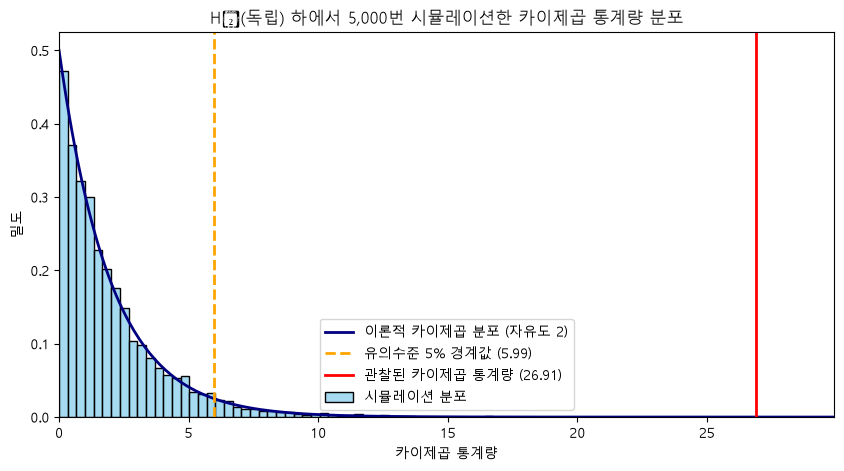

In [45]:
# [문제 4] Q4. 시뮬레이션으로 얻은 카이제곱 통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 카이제곱 통계량을 세로선으로 함께 표시해 봅시다.
plt.figure(figsize=(10, 5))

# 시뮬레이션 카이제곱 통계량 분포
sns.histplot(sim_chi2, bins=50, stat='density', color='skyblue', label='시뮬레이션 분포')

# 참고: 이론적인 카이제곱 분포(자유도 2) 곡선
x_vals = np.linspace(0, chi2_stat + 3, 300)
plt.plot(x_vals, stats.chi2.pdf(x_vals, df=dof), color='navy', linewidth=2,
         label=f'이론적 카이제곱 분포 (자유도 {dof})')

# 유의수준 5% 경계값 (이 값보다 크면 귀무가설 기각)
critical = stats.chi2.ppf(0.95, df=dof)
plt.axvline(critical, color='orange', linestyle='--', linewidth=2,
            label=f'유의수준 5% 경계값 ({critical:.2f})')

# 실제 관찰된 카이제곱 통계량
plt.axvline(chi2_stat, color='red', linestyle='-', linewidth=2,
            label=f'관찰된 카이제곱 통계량 ({chi2_stat:.2f})')

plt.xlim(0, chi2_stat + 3)   # 관찰값이 화면에 보이도록 x축 범위 설정
plt.title(f'H₀(독립) 하에서 {n_sim:,}번 시뮬레이션한 카이제곱 통계량 분포')
plt.xlabel('카이제곱 통계량')
plt.ylabel('밀도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?
> 기대 빈도는 **"연령대와 선호 장르가 서로 관련이 없다면(독립이라면) 각 칸에 몇 명이 있어야 하는가"**를 계산한 값입니다.
> 전체 300명 중 액션과 로맨스를 고른 비율이 각각 50%이므로, 독립이라면 어느 연령대든 50:50으로 나뉘어야 합니다.
> 예를 들어 20대는 100명이므로 액션 50명, 로맨스 50명이 기대 빈도가 됩니다. 계산식은 (행 합계 × 열 합계) ÷ 전체입니다.
> 카이제곱 통계량은 각 칸의 (관측 빈도 − 기대 빈도)² ÷ 기대 빈도를 모두 더한 값이므로,
> 관측 빈도와 기대 빈도의 **차이가 클수록 카이제곱 통계량은 커집니다.**
> 즉, 통계량이 클수록 실제 데이터가 "독립인 세상"의 모습에서 많이 벗어나 있다는 뜻입니다.


- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?
> **연령대와 장르가 서로 독립이라고 가정했을 때, 우연만으로 나올 수 있는 카이제곱 통계량들의 분포**를 시각화한 것입니다.
> 300명의 연령대와 장르를 각각 독립적으로 무작위 할당하는 과정을 5,000번 반복해 얻은 통계량들이며,
> 이론적으로는 자유도 2인 카이제곱 분포를 따릅니다. 통계량이 항상 0 이상이므로 오른쪽으로 꼬리가 긴 모양이 나타납니다.
> 실제 관찰된 통계량 26.91은 **극단적인 값**입니다. 시뮬레이션 통계량은 대부분 0~6 사이에 몰려 있고 최댓값도 16.76이었으며,
> 5,000번 중 26.91 이상이 나온 경우는 한 번도 없었습니다.

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?
> **네, 결론 내릴 수 있습니다.**
> 카이제곱 검정의 p-값이 약 0.0000014로 유의수준 0.05보다 훨씬 작으므로 귀무가설("두 변수는 독립이다")을 기각합니다.
> 이는 연령대와 장르가 정말 관련이 없다면 이 정도로 치우친 분할표가 나올 확률이 극히 낮다는 뜻입니다.
> 시각적으로도 관찰된 통계량(26.91)이 유의수준 5% 경계값(5.99)보다 한참 오른쪽에 위치합니다.
> 따라서 **연령대에 따라 선호하는 영화 장르에 통계적으로 유의미한 차이가 있다**고 볼 수 있습니다.


- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?
> 관측 빈도와 기대 빈도를 비교하면 연령대별 특징이 드러납니다.
> 20대는 기대(50명)보다 액션을 훨씬 많이(70명) 선택했고, 40대는 기대(45명)보다 로맨스를 더 많이(60명) 선택했습니다.
> 30대는 로맨스가 약간 많지만(60명 vs 기대 55명) 기대 빈도와 큰 차이가 없어 비교적 고르게 선호합니다.
> 이를 바탕으로 다음과 같은 전략을 세울 수 있습니다.
> **20대 대상**: 대학가 인근 지점이나 금요일 밤·주말 심야 시간대에 액션 영화 상영관을 늘리고, 액션 개봉작에 맞춘 학생 할인·SNS 이벤트를 진행합니다.
> **40대 대상**: 평일 낮이나 주말 오후 시간대에 로맨스 영화를 배치하고, 부부·커플 관람권 같은 로맨스 장르 연계 프로모션을 기획합니다.
> **30대 대상**: 특정 장르에 치우치지 않으므로 두 장르를 모두 묶은 멤버십 혜택이나 장르 다양성을 강조한 마케팅이 효과적일 수 있습니다.
> 다만 이 검정은 연관성이 있다는 것만 알려줄 뿐 원인을 밝혀주지는 않으므로, 실제 예매 데이터 등으로 효과를 추가 검증하는 것이 좋습니다.

In [ ]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

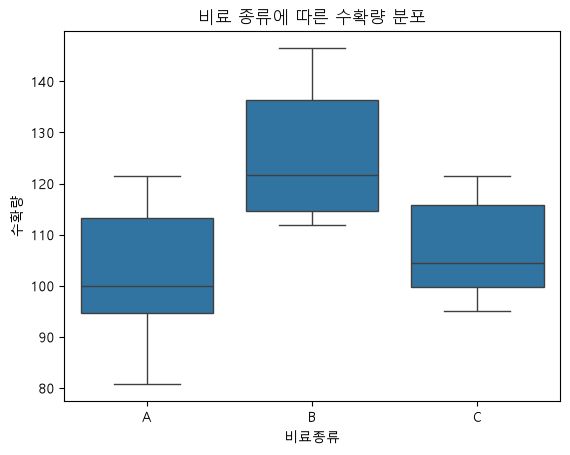

In [46]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

In [47]:
# [문제 5] Q1. 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.

# 여기에 코드를 작성해주세요.

from scipy import stats

print("비료별 평균 수확량:")
print(df.groupby('비료종류')['수확량'].mean().round(2))

f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

print(f"\nF-통계량: {f_stat:.4f}")
print(f"p-값: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print("→ 귀무가설 기각: 적어도 하나의 비료는 평균 수확량이 다릅니다.")
else:
    print("→ 귀무가설 기각 실패: 세 비료의 평균 수확량이 다르다고 할 근거가 부족합니다.")

비료별 평균 수확량:
비료종류
A    102.30
B    125.98
C    107.15
Name: 수확량, dtype: float64

F-통계량: 10.3455
p-값: 0.0005
→ 귀무가설 기각: 적어도 하나의 비료는 평균 수확량이 다릅니다.


In [48]:
# [문제 5] Q2. ANOVA의 p-값이 유의수준 0.05보다 작을 경우에만
# Tukey's HSD 사후분석을 수행하고 결과를 출력해봅시다.
# 힌트: pairwise_tukeyhsd(endog=수확량, groups=비료종류, alpha=0.05)

# 여기에 코드를 작성해주세요.

from statsmodels.stats.multicomp import pairwise_tukeyhsd

if p_value < alpha:
    tukey_result = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=0.05)
    print(tukey_result)
else:
    print("ANOVA 결과가 유의하지 않으므로 사후분석을 수행하지 않습니다.")

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------


In [49]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

# 여기에 코드를 작성해주세요.

np.random.seed(42)

n_sim = 5000
n_per_group = 10

# 모든 데이터를 합친 평균과 표준편차 → H₀ 모집단
all_yield = df['수확량']
pooled_mean = all_yield.mean()
pooled_std = all_yield.std(ddof=1)

print(f"H₀ 모집단 평균: {pooled_mean:.2f}")
print(f"H₀ 모집단 표준편차: {pooled_std:.2f}")

sim_f = []  # 각 반복의 F-통계량 저장

for i in range(n_sim):
    # 같은 모집단에서 10개씩 3개의 가상 그룹 생성
    fake_a = np.random.normal(loc=pooled_mean, scale=pooled_std, size=n_per_group)
    fake_b = np.random.normal(loc=pooled_mean, scale=pooled_std, size=n_per_group)
    fake_c = np.random.normal(loc=pooled_mean, scale=pooled_std, size=n_per_group)

    # 가상 그룹으로 ANOVA 수행 후 F-통계량 저장
    f, _ = stats.f_oneway(fake_a, fake_b, fake_c)
    sim_f.append(f)

sim_f = np.array(sim_f)

print(f"\n실제 F-통계량: {f_stat:.2f}")
print(f"시뮬레이션 F-통계량 평균: {sim_f.mean():.2f}")
print(f"시뮬레이션 F-통계량 상위 5% 경계값: {np.percentile(sim_f, 95):.2f}")
print(f"시뮬레이션 F-통계량 최댓값: {sim_f.max():.2f}")

count = np.sum(sim_f >= f_stat)
print(f"\n실제 F-통계량({f_stat:.2f}) 이상인 경우: {count}번 / {n_sim}번")
print(f"시뮬레이션 p-값: {count / n_sim:.4f}")

H₀ 모집단 평균: 111.81
H₀ 모집단 표준편차: 15.77

실제 F-통계량: 10.35
시뮬레이션 F-통계량 평균: 1.11
시뮬레이션 F-통계량 상위 5% 경계값: 3.51
시뮬레이션 F-통계량 최댓값: 13.58

실제 F-통계량(10.35) 이상인 경우: 3번 / 5000번
시뮬레이션 p-값: 0.0006


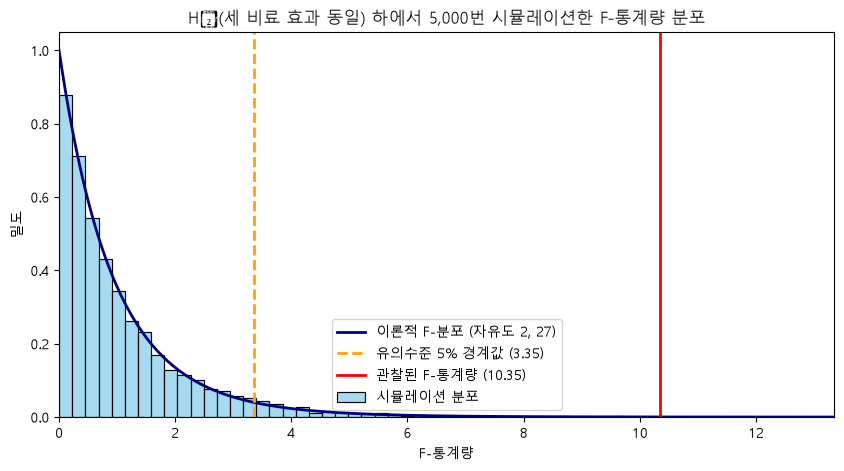

In [50]:
# [문제 5] Q4. 시뮬레이션으로 얻은 F-통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 F-통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

plt.figure(figsize=(10, 5))

# 시뮬레이션 F-통계량 분포
sns.histplot(sim_f, bins=60, stat='density', color='skyblue', label='시뮬레이션 분포')

# 참고: 이론적인 F-분포 곡선 (자유도: 그룹 수-1, 전체 개수-그룹 수)
df_between = 3 - 1          # 2
df_within = 30 - 3          # 27
x_vals = np.linspace(0, f_stat + 3, 300)
plt.plot(x_vals, stats.f.pdf(x_vals, df_between, df_within), color='navy', linewidth=2,
         label=f'이론적 F-분포 (자유도 {df_between}, {df_within})')

# 유의수준 5% 경계값
critical = stats.f.ppf(0.95, df_between, df_within)
plt.axvline(critical, color='orange', linestyle='--', linewidth=2,
            label=f'유의수준 5% 경계값 ({critical:.2f})')

# 실제 관찰된 F-통계량
plt.axvline(f_stat, color='red', linestyle='-', linewidth=2,
            label=f'관찰된 F-통계량 ({f_stat:.2f})')

plt.xlim(0, f_stat + 3)
plt.title(f'H₀(세 비료 효과 동일) 하에서 {n_sim:,}번 시뮬레이션한 F-통계량 분포')
plt.xlabel('F-통계량')
plt.ylabel('밀도')
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q5. 분석 결과를 바탕으로 연구소에 어떤 비료를 추천하시겠습니까?
#
# [추천] 비료 B
#
# [근거]
# 1. ANOVA 결과(F=10.35, p=0.0005), 세 비료의 평균 수확량에는 통계적으로 유의미한 차이가 있다.
#    시뮬레이션에서도 효과가 같다면 이 정도 F-통계량은 5,000번 중 3번만 나와 우연으로 보기 어렵다.
# 2. Tukey's HSD 사후분석 결과, 비료 B(평균 125.98)는 비료 A(102.30)보다 약 23.7,
#    비료 C(107.15)보다 약 18.8 더 많이 수확했으며, 두 차이 모두 유의미했다(p-adj = 0.0006, 0.0054).
# 3. 비료 A와 C는 평균 차이가 약 4.8로 유의미하지 않았다(p-adj = 0.6569).
#    즉 A와 C는 사실상 비슷한 효과이고, B만 뚜렷하게 우수하다.
# 4. B의 신뢰구간 하한도 A 대비 +10.0, C 대비 +5.2로 0보다 크므로,
#    보수적으로 보더라도 B가 다른 두 비료보다 수확량이 많을 가능성이 높다.
#
# [추가 고려사항]
# - 비용: B가 A, C보다 훨씬 비싸다면 수확량 증가분이 비용 증가분을 상쇄하는지 따져봐야 한다.
#   B를 쓸 수 없는 상황이라면 A와 C는 효과 차이가 없으므로 더 저렴한 쪽을 선택하면 된다.
# - 안정성: B는 표준편차(13.7)가 C(9.7)보다 커서 밭에 따라 수확량 편차가 클 수 있다.
# - 표본 크기: 비료당 밭 10개로 규모가 작으므로, 다른 지역·토양·계절에서 추가 실험으로
#   효과가 재현되는지 확인한 뒤 대규모 도입을 결정하는 것이 바람직하다.

**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?
> ANOVA의 p-값은 약 0.0005로 유의수준 0.05보다 작으므로 귀무가설("세 비료의 평균 수확량은 모두 같다")을 기각합니다.
> 따라서 이 결과는 **"적어도 하나의 비료는 평균 수확량이 다르다"**는 뜻입니다.
> 주의할 점은 ANOVA가 "어딘가에 차이가 있다"는 것만 알려줄 뿐, **어떤 비료끼리 다른지, 세 비료가 모두 서로 다른지는 알려주지 않는다**는 것입니다.
> 예를 들어 B만 다르고 A와 C는 같은 경우에도 귀무가설은 기각됩니다. 그래서 구체적인 차이를 확인하려면 사후분석이 필요합니다.


- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?
> `reject`가 True인 조합은 **A-B**(p-adj=0.0006)와 **B-C**(p-adj=0.0054)입니다.
> 이는 해당 두 비료의 평균 수확량이 **통계적으로 유의미하게 다르다**는 의미로, "두 비료의 평균이 같다"는 귀무가설을 기각했다는 뜻입니다.
> 반면 A-C 조합은 False(p-adj=0.6569)로, 두 비료의 평균 수확량이 다르다고 볼 근거가 부족합니다.
> 종합하면 **비료 B만 다른 두 비료와 뚜렷하게 다르고, A와 C는 비슷한 효과**를 보인다고 해석할 수 있습니다.
> 이것이 ANOVA에서 귀무가설이 기각된 이유입니다.


- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?
> `meandiff`는 **group2의 평균에서 group1의 평균을 뺀 값**으로, 차이의 크기와 방향을 알려줍니다.
> A-B는 +23.68로 B가 A보다 약 23.7 더 많이 수확했고, B-C는 −18.83으로 C가 B보다 약 18.8 적게 수확했다는 뜻입니다.
> A-C는 +4.84로 C가 A보다 약간 많지만, 이 차이는 유의미하지 않았습니다.
> 신뢰구간은 실제 평균 차이가 있을 것으로 추정되는 범위입니다.
> **신뢰구간이 0을 포함하면** "차이가 0일 수도 있다", 즉 두 비료의 효과가 같을 가능성을 배제할 수 없으므로 유의미한 차이가 아닙니다.
> A-C의 신뢰구간(−8.79 ~ 18.48)은 0을 포함하므로 reject가 False입니다.
> **신뢰구간이 0을 포함하지 않으면** 차이가 한쪽 방향으로 확실하다는 뜻입니다.
> A-B(10.04 ~ 37.31)는 전부 양수라 B가 확실히 더 많고, B-C(−32.47 ~ −5.20)는 전부 음수라 C가 확실히 더 적습니다.
> 따라서 신뢰구간의 0 포함 여부와 `reject` 결과는 항상 일치합니다.


- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?
> 표본 크기가 작으면 다음과 같은 한계가 있습니다.
> 첫째, **추정이 부정확합니다.** 신뢰구간의 폭이 넓어지는데, 실제로 A-B 차이의 신뢰구간은 10.04 ~ 37.31로 폭이 약 27에 달합니다.
> B가 더 낫다는 건 확실하지만, 정확히 얼마나 더 나은지는 불확실합니다.
> 둘째, **작은 차이를 놓칠 수 있습니다(검정력이 낮음).** A와 C의 차이(4.84)가 유의하지 않게 나온 것은
> 실제로 차이가 없어서일 수도 있지만, 표본이 작아서 실제로 존재하는 차이를 잡아내지 못했을 수도 있습니다(제2종 오류).
> 셋째, **결과가 몇몇 밭에 크게 좌우됩니다.** 유독 토양이 좋거나 나쁜 밭이 한두 개만 있어도 평균이 크게 흔들릴 수 있습니다.
> 넷째, **가정 검정의 신뢰도도 떨어집니다.** 표본이 작으면 정규성 검정이 정규성 위반을 잘 감지하지 못하며,
> 비료 B의 Shapiro 검정 p-값(0.086)은 0.05에 비교적 가까웠습니다.
> 개선 방법은 다음과 같습니다.
> - 비료별 밭의 수를 늘립니다. 실험 전에 **검정력 분석**으로 원하는 차이를 잡아내는 데 필요한 표본 크기를 미리 계산하면 좋습니다.
> - 다른 지역, 토양, 계절에서 실험을 **반복**하여 결과가 재현되는지 확인합니다.
> - 밭을 비료에 **무작위로 배정**하고, 토양 상태처럼 수확량에 영향을 주는 요인이 있다면 비슷한 밭끼리 묶어 비교하는(블록 설계) 방법으로 오차를 줄입니다.

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.